# What drives heavy traffic? Hourly volume on Interstate 94 (Minneapolis-St Paul), 2012-2018
**Data.** 48,204 hourly records of westbound I-94 traffic at a Minnesota DoT station, joined with weather and public holidays (UCI Metro Interstate Traffic Volume dataset).

**Questions.** When is traffic heaviest? How much do weather and holidays change it **after controlling for the time of day, weekday and season**? Can a model forecast next-year hourly volume better than "same hour last week"?

The original version of this analysis was a descriptive exercise. This one adds data cleaning, controlled effect estimates and an out-of-sample forecast.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
raw = pd.read_csv("data/metro_interstate_traffic.csv.gz", parse_dates=["date_time"])
print(raw.shape)
issues = {"duplicate timestamps (several weather rows per hour)": raw.date_time.duplicated().sum(),
          "temperature recorded as 0 K": (raw.temp == 0).sum(), "rain_1h > 100 mm (sensor error)": (raw.rain_1h > 100).sum()}
pd.Series(issues, name="rows")

(48204, 9)


duplicate timestamps (several weather rows per hour)    7629
temperature recorded as 0 K                               10
rain_1h > 100 mm (sensor error)                            1
Name: rows, dtype: int64

40,575 unique hours; 22.8% of hours missing in the period


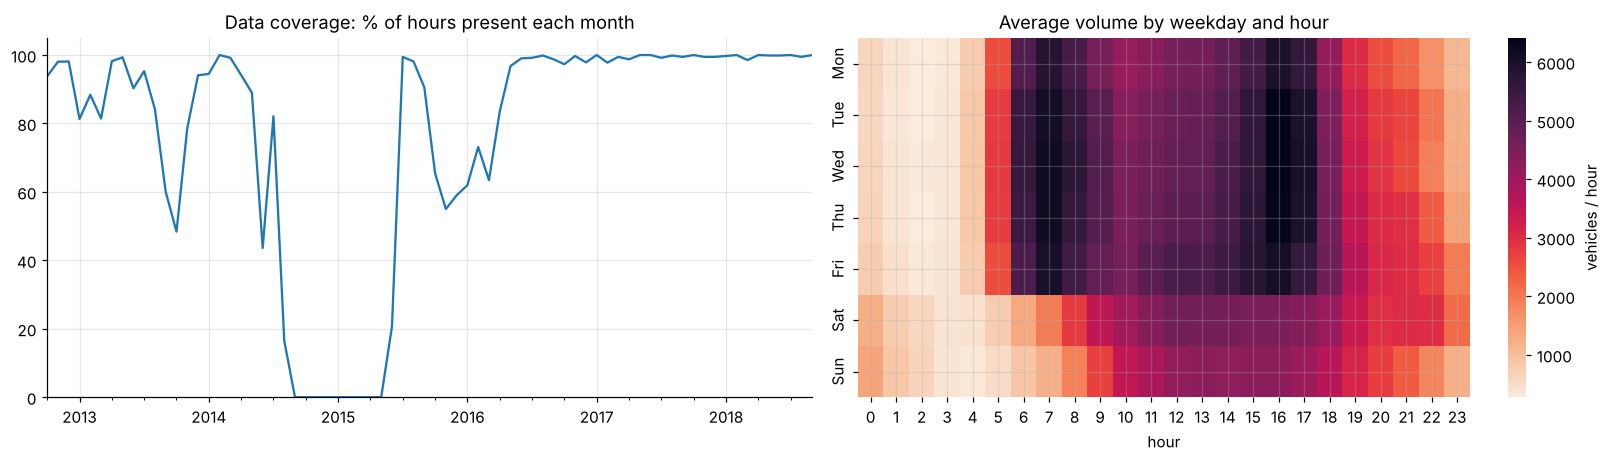

53 holiday days


In [2]:
df = raw.sort_values("date_time").drop_duplicates("date_time").set_index("date_time")
df.loc[df.temp == 0, "temp"] = np.nan; df.loc[df.rain_1h > 100, "rain_1h"] = np.nan
df["temp_c"] = df.temp - 273.15
full = pd.date_range(df.index.min(), df.index.max(), freq="h")
cover = df.reindex(full).traffic_volume.notna().resample("ME").mean()
print(f"{len(df):,} unique hours; {100 * (1 - len(df) / len(full)):.1f}% of hours missing in the period")
# holidays are only flagged at midnight: extend the flag to the whole day
hol_days = df.index[df.holiday.notna() & (df.holiday != "None")].normalize().unique()
df["holiday_day"] = df.index.normalize().isin(hol_days)
df["hour"], df["dow"], df["month"], df["year"] = df.index.hour, df.index.dayofweek, df.index.month, df.index.year
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
(100 * cover).plot(ax=axes[0], title="Data coverage: % of hours present each month"); axes[0].set_ylim(0, 105)
hm = df.pivot_table(index="dow", columns="hour", values="traffic_volume", aggfunc="mean")
hm.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
sns.heatmap(hm, cmap="rocket_r", ax=axes[1], cbar_kws={"label": "vehicles / hour"}); axes[1].set_title("Average volume by weekday and hour")
plt.tight_layout(); plt.savefig(IMG / "coverage_heatmap.png", bbox_inches="tight"); plt.show()
print(f"{len(hol_days)} holiday days")

## Weather and holiday effects, holding the clock and calendar fixed
A log-linear regression on daytime hours (07:00-19:00) with hour × weekday, month and year fixed effects. Coefficients are converted to % changes relative to clear weather on an ordinary day.

R² = 0.619, n = 21,830


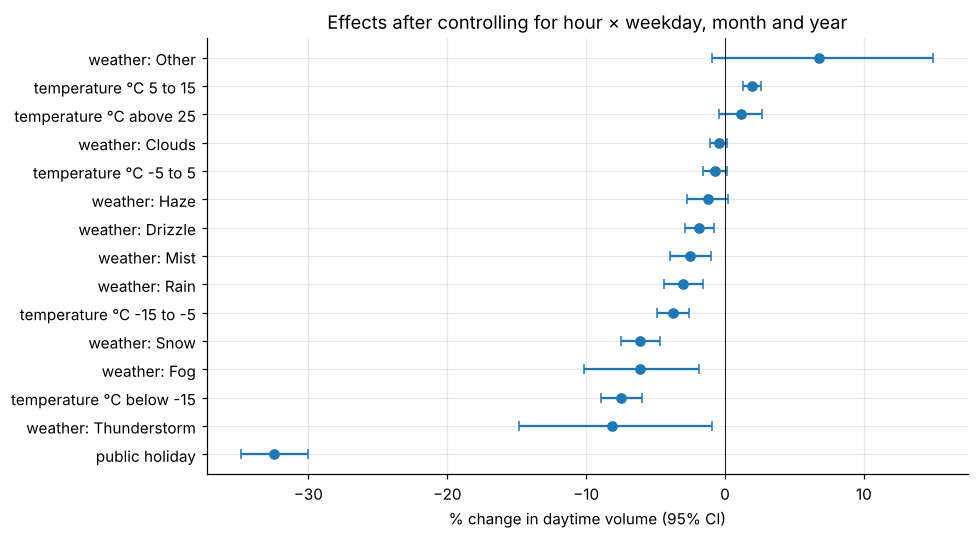

,effect_%,low_%,high_%
public holiday,-32.5,-34.8,-30.0
weather: Thunderstorm,-8.1,-14.8,-0.9
temperature °C below -15,-7.5,-9.0,-6.0
weather: Fog,-6.1,-10.1,-1.9
weather: Snow,-6.1,-7.5,-4.7
temperature °C -15 to -5,-3.8,-4.9,-2.6
weather: Rain,-3.0,-4.4,-1.6
weather: Mist,-2.5,-4.0,-1.0
weather: Drizzle,-1.8,-2.9,-0.8
weather: Haze,-1.2,-2.7,0.2


In [3]:
d = df[(df.hour.between(7, 19)) & (df.traffic_volume > 0)].dropna(subset=["temp_c"]).copy()
d["weather"] = d.weather_main.where(d.weather_main.isin(["Clear", "Clouds", "Rain", "Snow", "Mist", "Drizzle", "Fog", "Thunderstorm", "Haze"]), "Other")
d["temp_band"] = pd.cut(d.temp_c, [-40, -15, -5, 5, 15, 25, 45], labels=["below -15", "-15 to -5", "-5 to 5", "5 to 15", "15 to 25", "above 25"]).astype(str)
fit = smf.ols("np.log(traffic_volume) ~ C(hour):C(dow) + C(month) + C(year) + holiday_day + C(weather, Treatment('Clear')) + C(temp_band, Treatment('15 to 25'))",
              data=d).fit(cov_type="HC1")
eff = fit.params.filter(regex="weather|holiday|temp_band"); ci = fit.conf_int().loc[eff.index]
tab = pd.DataFrame({"effect_%": 100 * (np.exp(eff) - 1), "low_%": 100 * (np.exp(ci[0]) - 1), "high_%": 100 * (np.exp(ci[1]) - 1)})
tab.index = (tab.index.str.replace(r"C\(weather, Treatment\('Clear'\)\)\[T\.", "weather: ", regex=True)
             .str.replace(r"C\(temp_band.*\[T\.", "temperature °C ", regex=True).str.replace("holiday_day[T.True]", "public holiday", regex=False).str.rstrip("]"))
print(f"R² = {fit.rsquared:.3f}, n = {int(fit.nobs):,}")
fig, ax = plt.subplots(figsize=(9, 5)); t = tab.sort_values("effect_%")
ax.errorbar(t["effect_%"], range(len(t)), xerr=[t["effect_%"] - t["low_%"], t["high_%"] - t["effect_%"]], fmt="o", capsize=3)
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.axvline(0, c="k", lw=.6)
ax.set_xlabel("% change in daytime volume (95% CI)"); ax.set_title("Effects after controlling for hour × weekday, month and year")
plt.tight_layout(); plt.savefig(IMG / "weather_effects.png", bbox_inches="tight"); plt.show()
tab.round(1).sort_values("effect_%")

## Forecasting 2018 hourly volume
Train on 2015-2017 (after the long data gap) and test on 2018. The model uses calendar features plus *observed* weather, so its score is an upper bound on what a real forecast with predicted weather would achieve.

test hours: 6,514
WAPE  same-hour-last-week: 10.2%   |   gradient boosting: 6.8%
on holiday days: naive 41.8% vs model 17.2%


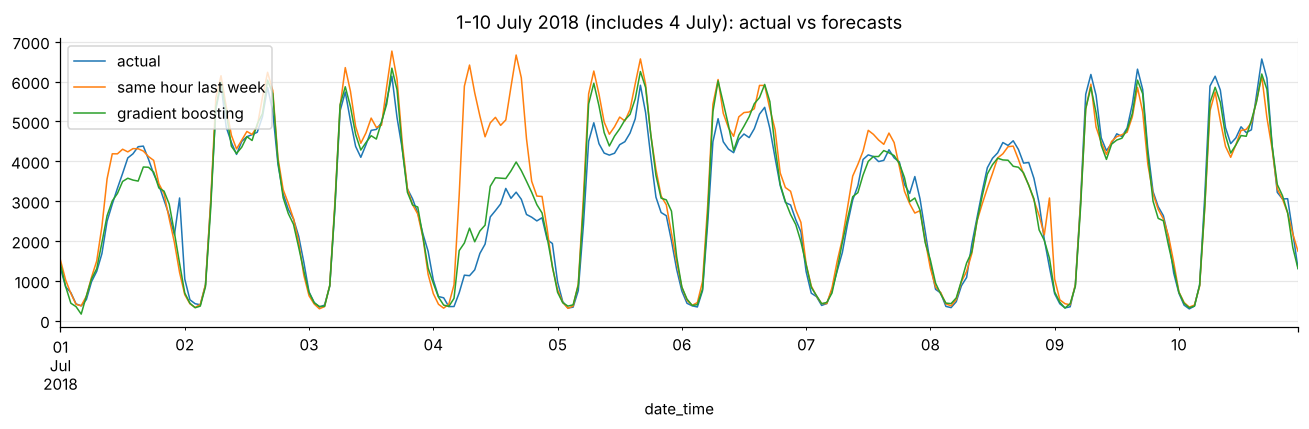

In [4]:
f = df.copy()
f["vol_lag_week"] = f.traffic_volume.reindex(f.index - pd.Timedelta(days=7)).values
f["weather_code"] = f.weather_main.astype("category").cat.codes
feats = ["hour", "dow", "month", "holiday_day", "temp_c", "rain_1h", "snow_1h", "clouds_all", "weather_code"]
tr, te = f[(f.index >= "2015-07-01") & (f.index < "2018-01-01")], f[f.index >= "2018-01-01"]
gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(tr[feats].astype(float), tr.traffic_volume)
te = te.assign(model=gb.predict(te[feats].astype(float)))
ev = te.dropna(subset=["vol_lag_week"])
wape = lambda a, p: 100 * np.abs(a - p).sum() / a.sum()
print(f"test hours: {len(ev):,}")
print(f"WAPE  same-hour-last-week: {wape(ev.traffic_volume, ev.vol_lag_week):.1f}%   |   gradient boosting: {wape(ev.traffic_volume, ev.model):.1f}%")
print(f"on holiday days: naive {wape(ev[ev.holiday_day].traffic_volume, ev[ev.holiday_day].vol_lag_week):.1f}% vs model {wape(ev[ev.holiday_day].traffic_volume, ev[ev.holiday_day].model):.1f}%")
wk = ev.loc["2018-07-01":"2018-07-10"]
ax = wk[["traffic_volume", "vol_lag_week", "model"]].plot(figsize=(12, 4), lw=1, title="1-10 July 2018 (includes 4 July): actual vs forecasts")
ax.legend(["actual", "same hour last week", "gradient boosting"]); plt.tight_layout(); plt.savefig(IMG / "forecast_week.png", bbox_inches="tight"); plt.show()

## Findings
* **Clean before you count.** 7,629 rows duplicate a timestamp (several weather descriptions for the same hour), there are 10 readings of 0 K and one 9,831 mm "rain" hour, and almost a year (autumn 2014 to mid-2015) is missing. Holidays are flagged only at midnight in the raw file, so a naive holiday analysis would see almost no effect.
* **Commuting dominates.** On weekdays traffic peaks at about 6,100 vehicles an hour at 07:00 and 6,200 at 16:00. Weekends have a single flatter midday plateau of about 4,400.
* **Controlled effects (daytime, vs clear weather on an ordinary day):** a public holiday cuts volume by **33%**. Thunderstorms (−8%), extreme cold below −15 °C (−8%), snow and fog (−6% each) and rain (−3%) matter less. Mild 5-15 °C days carry about 2% *more* traffic. The weather effects are modest because most trips are commutes that happen anyway.
* **Forecast:** on 2018 data the gradient-boosting model's error (WAPE) is **6.8% vs 10.2%** for "same hour last week". The gain is concentrated on holidays (17% vs 42%), where the naive method repeats a normal day, as the 4 July chart shows. Because the model uses *observed* weather, this is an upper bound for a live forecast.